In [53]:
data = {
    "Annual_Income": [15, 16, 17, 60, 62, 65, 85, 88, 90],
    "Spending_Score": [20, 25, 18, 60, 65, 62, 85, 90, 88]
}

df = pd.DataFrame(data)

df

,Annual_Income,Spending_Score
0,15,20
1,16,25
2,17,18
3,60,60
4,62,65
5,65,62
6,85,85
7,88,90
8,90,88


In [54]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns)

# Check data types and missing values
print("\nDataset Information:")
df.info()

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Get statistical summary
print("\nStatistical Summary:")
df.describe()

Dataset Shape: (9, 2)

Column Names:
Index(['Annual_Income', 'Spending_Score'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Annual_Income   9 non-null      int64
 1   Spending_Score  9 non-null      int64
dtypes: int64(2)
memory usage: 272.0 bytes

Missing Values:
Annual_Income     0
Spending_Score    0
dtype: int64

Statistical Summary:


,Annual_Income,Spending_Score
count,9.000000,9.000000
mean,55.333333,57.000000
std,31.527766,29.253205
min,15.000000,18.000000
25%,17.000000,25.000000
50%,62.000000,62.000000
75%,85.000000,85.000000
max,90.000000,90.000000


In [55]:
# Select the features for clustering
X = df[["Annual_Income", "Spending_Score"]]

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Display the scaled data
print("Original Data:")
print(X.head())

print("\nScaled Data:")
print(X_scaled[:5])

Original Data:
   Annual_Income  Spending_Score
0             15              20
1             16              25
2             17              18
3             60              60
4             62              65

Scaled Data:
[[-1.35689794 -1.3415428 ]
 [-1.32325585 -1.16025323]
 [-1.28961375 -1.41405862]
 [ 0.15699646  0.10877374]
 [ 0.22428065  0.29006331]]


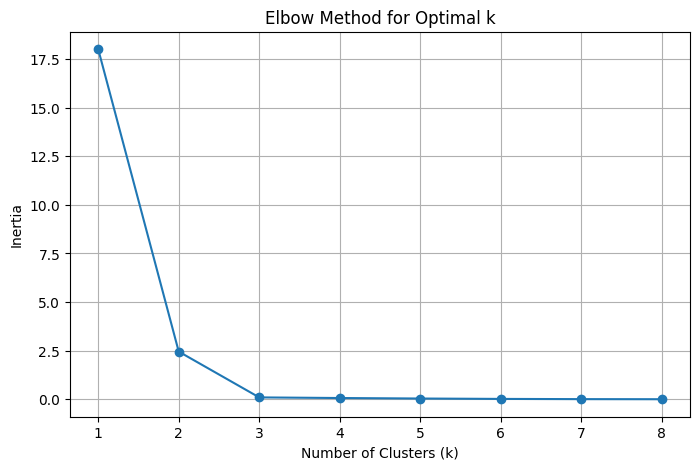

Inertia values: [18.0, 2.45351402895903, 0.09842027625877962, 0.06686900544370514, 0.0407737838071373, 0.02079462974164003, 0.009785708113712953, 0.004892854056856462]


In [56]:
inertia_values = []

for k in range(1, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

# Plot the Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 9), inertia_values, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.xticks(range(1, 9))
plt.grid(True)
plt.show()

print("Inertia values:", inertia_values)

In [57]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans.fit(X_scaled)

labels = kmeans.labels_

print("Cluster Labels:", labels)

Cluster Labels: [1 1 1 0 0 0 2 2 2]


In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [59]:
df["Cluster"] = labels

df

,Annual_Income,Spending_Score,Cluster
0,15,20,1
1,16,25,1
2,17,18,1
3,60,60,0
4,62,65,0
5,65,62,0
6,85,85,2
7,88,90,2
8,90,88,2


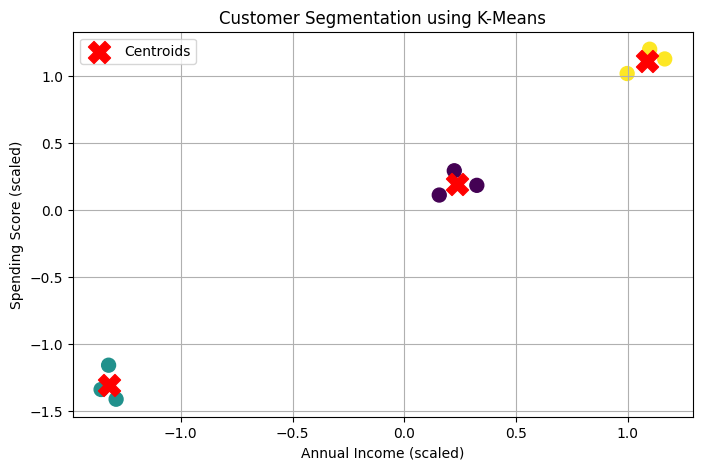

In [60]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap="viridis",
    s=100
)

# Plot the cluster centroids
centroids = kmeans.cluster_centers_

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=250,
    color="red",
    label="Centroids"
)

plt.xlabel("Annual Income (scaled)")
plt.ylabel("Spending Score (scaled)")
plt.title("Customer Segmentation using K-Means")
plt.legend()
plt.grid(True)
plt.show()

In [61]:
# Centroids in scaled coordinates
print("Scaled Centroids:")
print(kmeans.cluster_centers_)

# Convert centroids back to the original scale
original_centroids = scaler.inverse_transform(
    kmeans.cluster_centers_
)

centroid_df = pd.DataFrame(
    original_centroids,
    columns=["Annual_Income", "Spending_Score"]
)

print("\nCentroids in Original Scale:")
print(centroid_df.round(2))

Scaled Centroids:
[[ 0.23549468  0.19337554]
 [-1.32325585 -1.30528488]
 [ 1.08776116  1.11190934]]

Centroids in Original Scale:
   Annual_Income  Spending_Score
0          62.33           62.33
1          16.00           21.00
2          87.67           87.67


In [62]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, labels)

print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.88
